In [1]:
import time
from collections.abc import Mapping
from dataclasses import dataclass
from datetime import datetime
from functools import partial
from pathlib import Path

import pandas as pd
import torch
from PIL import Image
from torch.utils.data import DataLoader, Dataset
from torch.utils.tensorboard import SummaryWriter
from torchmetrics.classification import MulticlassPrecision, MulticlassRecall
from torchvision.datasets import ImageFolder
from torchvision.transforms import v2

from mlkit.core.callbacks import Callback, ModelCheckpoint, ProgressLogger
from mlkit.core.history import History
from mlkit.core.task import OptimizerFactory
from mlkit.core.trainer import Trainer
from mlkit.data.splitter import StratifiedSplitter
from mlkit.data.subsets import TransformSubset
from mlkit.metrics.collections import multiclass_metrics
from mlkit.blocks.conv import ConvBlockConfig
from mlkit.blocks.linear import LinearBlockConfig
from mlkit.models.cnn_classifier import CNNClassifier, CNNConfig
from mlkit.tasks.classification import ClassificationTask
from mlkit.utils.logs import setup_logging
from mlkit.utils.seed import seed_everything
from mlkit.visual.confusion import confusion_matrix, plot_confusion_matrix
from mlkit.visual.curves import plot_comparison
from mlkit.visual.images import plot_image_grid
from mlkit.visual.saver import FigureSaver
from mlkit.visual.style import use_style

setup_logging()
use_style()

DATASET_PATH = Path("../../datasets/raw/BrainTumorMRI")
TRAINING_PATH = DATASET_PATH / "Training"
TESTING_PATH = DATASET_PATH / "Testing"

SEED = 42
IMAGE_SIZE = 128
BATCH_SIZE = 32
EPOCHS = 30
VAL_FRACTION = 0.15
CACHE_WORKERS = 2

RUN_NAME = f"lab1_part2_{datetime.now():%Y%m%d_%H%M%S}"
saver = FigureSaver(Path("artifacts") / RUN_NAME)

In [2]:
raw_train = ImageFolder(TRAINING_PATH)
raw_test = ImageFolder(TESTING_PATH)
class_names: list[str] = raw_train.classes

counts = pd.DataFrame(
    {
        "Training": pd.Series(raw_train.targets).value_counts().sort_index().to_numpy(),
        "Testing": pd.Series(raw_test.targets).value_counts().sort_index().to_numpy(),
    },
    index=class_names,
)
counts.loc["total"] = counts.sum()
counts

,Training,Testing
glioma,1400,400
meningioma,1400,400
notumor,1400,400
pituitary,1400,400
total,5600,1600


In [3]:
def describe(path: str) -> tuple[int, int, str]:
    with Image.open(path) as image:
        return image.width, image.height, image.mode


sizes = pd.DataFrame([describe(path) for path, _ in raw_train.samples], columns=["width", "height", "mode"])
print("Color modes:", sizes["mode"].value_counts().to_dict())
print("Most common sizes:", sizes.groupby(["width", "height"]).size().nlargest(3).to_dict())
sizes[["width", "height"]].describe().round(1)

Колірні режими: {'RGB': 3238, 'L': 2358, 'RGBA': 3, 'P': 1}
Найчастіші розміри: {(512, 512): 4012, (225, 225): 253, (630, 630): 69}


,width,height
count,5600.0,5600.0
mean,458.5,462.3
std,129.6,123.6
min,150.0,168.0
25%,512.0,512.0
50%,512.0,512.0
75%,512.0,512.0
max,1375.0,1446.0


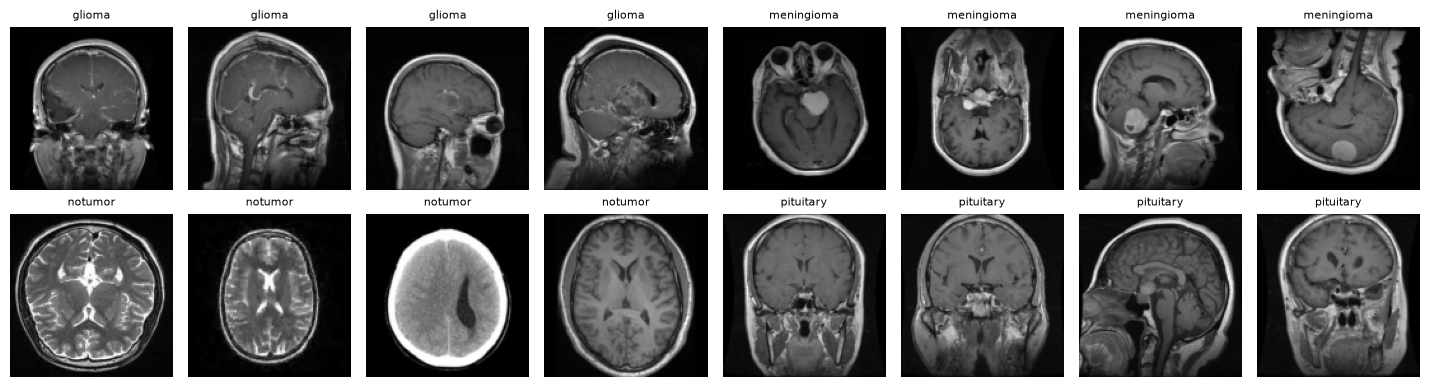

In [4]:
preview = v2.Compose([v2.Grayscale(), v2.Resize((IMAGE_SIZE, IMAGE_SIZE)), v2.ToImage(), v2.ToDtype(torch.float32, scale=True)])

examples = [
    index
    for label in range(len(class_names))
    for index in [i for i, target in enumerate(raw_train.targets) if target == label][:4]
]
saver.save(
    plot_image_grid(
        torch.stack([preview(raw_train[i][0]) for i in examples]),
        [class_names[raw_train.targets[i]] for i in examples],
    ),
    "samples",
);

In [5]:
class CachedImages(Dataset[tuple[torch.Tensor, int]]):
    def __init__(self, images: torch.Tensor, labels: list[int]) -> None:
        self.images = images
        self.labels = labels

    def __len__(self) -> int:
        return len(self.labels)

    def __getitem__(self, index: int) -> tuple[torch.Tensor, int]:
        return self.images[index], self.labels[index]


load = v2.Compose([v2.Grayscale(), v2.Resize((IMAGE_SIZE, IMAGE_SIZE)), v2.ToImage()])


def cache(path: Path) -> CachedImages:
    folder = ImageFolder(path, transform=load)
    batches = list(DataLoader(folder, batch_size=256, num_workers=CACHE_WORKERS))
    images = torch.cat([images for images, _ in batches])
    labels: list[int] = torch.cat([labels for _, labels in batches]).tolist()
    return CachedImages(images, labels)


start = time.perf_counter()
train_cache = cache(TRAINING_PATH)
test_cache = cache(TESTING_PATH)
print(f"Cached in {time.perf_counter() - start:.0f} s: train {tuple(train_cache.images.shape)}, "
      f"test {tuple(test_cache.images.shape)}, {train_cache.images.dtype}")

Кешовано за 21 с: train (5600, 1, 128, 128), test (1600, 1, 128, 128), torch.uint8


In [6]:
to_float = v2.ToDtype(torch.float32, scale=True)
train_transform = v2.Compose([
    v2.RandomAffine(degrees=10, translate=(0.05, 0.05)),
    v2.RandomHorizontalFlip(),
    to_float,
])

splitter = StratifiedSplitter((1 - VAL_FRACTION, VAL_FRACTION), seed=SEED)
train_idx, val_idx = splitter.split(train_cache.labels)
train_ds = TransformSubset(train_cache, train_idx, train_transform)
val_ds = TransformSubset(train_cache, val_idx, to_float)
test_ds = TransformSubset(test_cache, range(len(test_cache)), to_float)

train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True, pin_memory=True)
val_loader = DataLoader(val_ds, batch_size=256, pin_memory=True)
test_loader = DataLoader(test_ds, batch_size=256, pin_memory=True)

print(f"train: {len(train_ds)}, val: {len(val_ds)}, test: {len(test_ds)}")

train: 4760, val: 840, test: 1600


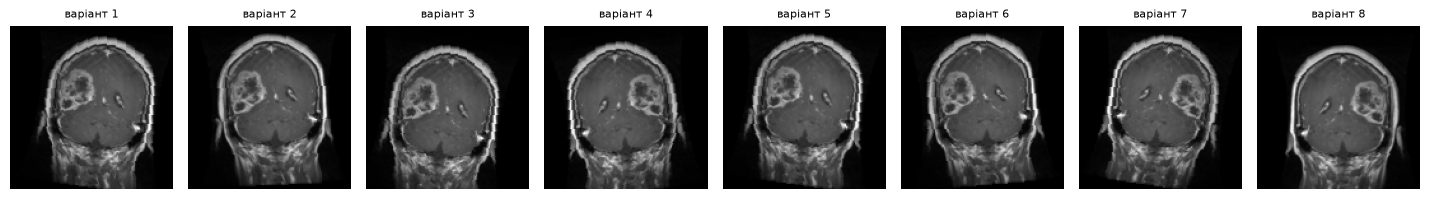

In [7]:
seed_everything(SEED)
augmented = torch.stack([train_ds[0][0] for _ in range(8)])
saver.save(plot_image_grid(augmented, [f"variant {i + 1}" for i in range(8)]), "augmentation");

In [8]:
cnn_config = CNNConfig(
    in_channels=1,
    input_size=(IMAGE_SIZE, IMAGE_SIZE),
    conv_configs=(
        ConvBlockConfig(out_channels=32, padding="same"),
        ConvBlockConfig(out_channels=64, padding="same"),
        ConvBlockConfig(out_channels=128, padding="same"),
        ConvBlockConfig(out_channels=128, padding="same"),
    ),
    linear_configs=(
        LinearBlockConfig(out_features=128, dropout=0.4),
        LinearBlockConfig(out_features=len(class_names), activation=None),
    ),
)
model = CNNClassifier(cnn_config)
print(model)
print(f"Parameters: {sum(p.numel() for p in model.parameters()):,}")

CNNClassifier(
  (conv_layers): Sequential(
    (0): Sequential(
      (0): Conv2d(1, 32, kernel_size=(3, 3), stride=(1, 1), padding=same)
      (1): ReLU()
      (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    )
    (1): Sequential(
      (0): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=same)
      (1): ReLU()
      (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    )
    (2): Sequential(
      (0): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=same)
      (1): ReLU()
      (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    )
    (3): Sequential(
      (0): Conv2d(128, 128, kernel_size=(3, 3), stride=(1, 1), padding=same)
      (1): ReLU()
      (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    )
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=8192, out_features=128, bias

In [9]:
class TensorBoardScalars(Callback):
    def __init__(self, writer: SummaryWriter) -> None:
        self.writer = writer

    def on_epoch_end(self, trainer: Trainer, epoch: int, logs: Mapping[str, float]) -> None:
        for key, value in logs.items():
            split, _, name = key.partition("/")
            self.writer.add_scalars(name, {split: value}, epoch)

In [10]:
OPTIMIZERS: dict[str, OptimizerFactory] = {
    "Adam": partial(torch.optim.Adam, lr=1e-3),
    "RMSprop": partial(torch.optim.RMSprop, lr=1e-3),
    "SGD_momentum": partial(torch.optim.SGD, lr=1e-2, momentum=0.9),
    "SGD": partial(torch.optim.SGD, lr=1e-2),
}


@dataclass
class RunResult:
    task: ClassificationTask
    history: History
    test: dict[str, float]
    best_epoch: int
    seconds: float


def run(name: str, optimizer: OptimizerFactory) -> RunResult:
    seed_everything(SEED)
    task = ClassificationTask(CNNClassifier(cnn_config), optimizer, multiclass_metrics(len(class_names)))
    best = ModelCheckpoint(task, monitor="val/loss", mode="min")
    writer = SummaryWriter(log_dir=f"runs/{RUN_NAME}/{name}")
    trainer = Trainer(callbacks=[ProgressLogger(every=5, metrics=["loss", "accuracy", "f1"]), TensorBoardScalars(writer), best])

    start = time.perf_counter()
    history = trainer.fit(task, train_loader, val_loader, epochs=EPOCHS)
    seconds = time.perf_counter() - start

    test = trainer.evaluate(task, test_loader)
    writer.close()
    return RunResult(task, history, test, best.best_epoch, seconds)

In [11]:
results: dict[str, RunResult] = {}
for name, optimizer in OPTIMIZERS.items():
    print(f"===== {name}")
    results[name] = run(name, optimizer)

===== Adam
Epoch 5 | train/loss 0.4551 train/accuracy 0.8244 train/f1 0.8217 train/precision 0.8207 train/recall 0.8244 val/loss 0.3441 val/accuracy 0.8607 val/f1 0.858 val/precision 0.8587 val/recall 0.8607 | 32.6s
Epoch 10 | train/loss 0.298 train/accuracy 0.8859 train/f1 0.8852 train/precision 0.8848 train/recall 0.8859 val/loss 0.2959 val/accuracy 0.8929 val/f1 0.8902 val/precision 0.8941 val/recall 0.8929 | 31.8s
Epoch 15 | train/loss 0.2116 train/accuracy 0.9147 train/f1 0.9145 train/precision 0.9145 train/recall 0.9147 val/loss 0.2028 val/accuracy 0.9214 val/f1 0.9216 val/precision 0.9229 val/recall 0.9214 | 31.7s
Epoch 20 | train/loss 0.1504 train/accuracy 0.9418 train/f1 0.9418 train/precision 0.9418 train/recall 0.9418 val/loss 0.1802 val/accuracy 0.9429 val/f1 0.9422 val/precision 0.9439 val/recall 0.9429 | 31.1s
Epoch 25 | train/loss 0.124 train/accuracy 0.955 train/f1 0.9551 train/precision 0.9552 train/recall 0.955 val/loss 0.1467 val/accuracy 0.956 val/f1 0.9558 val/prec

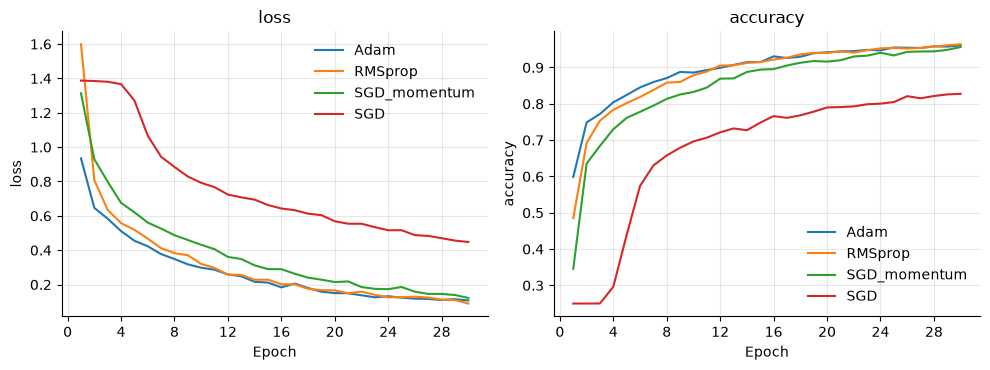

In [12]:
histories = {name: result.history for name, result in results.items()}
saver.save(plot_comparison(histories, ["loss", "accuracy"], splits=("train",)), "convergence_train");

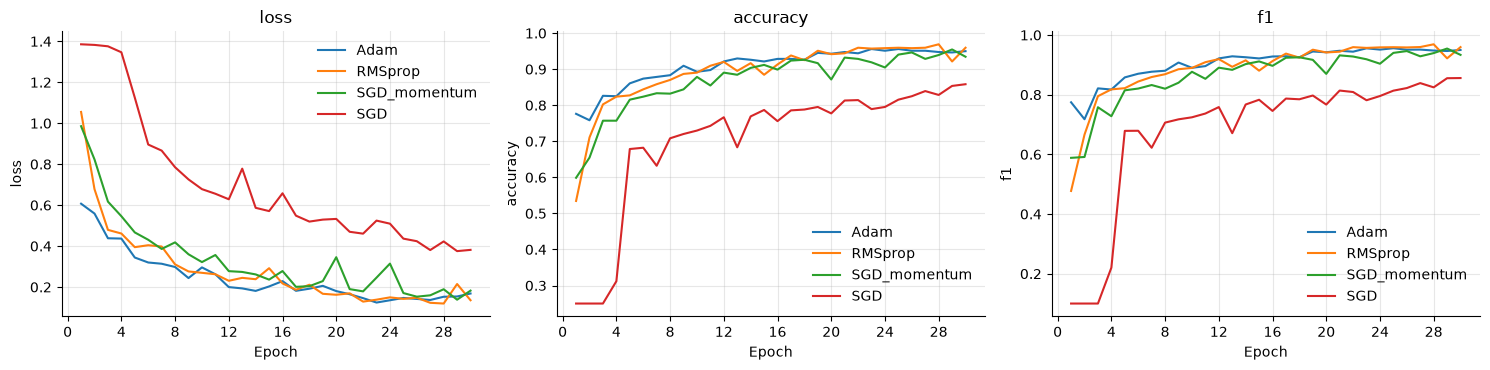

In [13]:
saver.save(plot_comparison(histories, ["loss", "accuracy", "f1"]), "convergence_val");

In [14]:
def epochs_to(history: History, key: str, threshold: float) -> int | None:
    epochs, values = history.series(key)
    return next((epoch for epoch, value in zip(epochs, values) if value >= threshold), None)


summary = pd.DataFrame({
    name: {
        "best epoch": result.best_epoch,
        "epochs to 90% val accuracy": epochs_to(result.history, "val/accuracy", 0.9),
        "best val loss": result.history.best("val/loss", "min")[1],
        "test loss": result.test["loss"],
        "test accuracy": result.test["accuracy"],
        "test precision": result.test["precision"],
        "test recall": result.test["recall"],
        "test f1": result.test["f1"],
        "training time, s": result.seconds,
    }
    for name, result in results.items()
}).T
summary.to_csv(saver.directory / "summary.csv")
summary.round(4)

,найкраща епоха,епох до 90% val accuracy,найкращий val loss,test loss,test accuracy,test precision,test recall,test f1,"час навчання, с"
Adam,23.0,9.0,0.1242,0.8545,0.9087,0.9137,0.9087,0.9067,190.7841
RMSprop,28.0,11.0,0.1194,0.8854,0.9250,0.9277,0.9250,0.9234,187.7127
SGD_momentum,29.0,14.0,0.1382,0.6643,0.9175,0.9187,0.9175,0.9154,184.7399
SGD,29.0,NaN,0.3754,0.7212,0.8044,0.8045,0.8044,0.8006,181.8199


Найкращий за test F1: RMSprop


,precision,recall,support
glioma,0.9605,0.7900,400
meningioma,0.9118,0.9300,400
notumor,0.8822,0.9925,400
pituitary,0.9564,0.9875,400


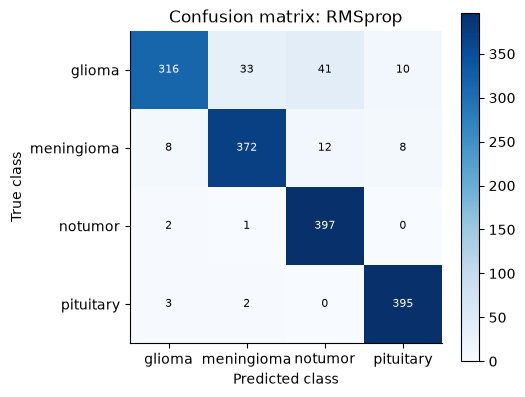

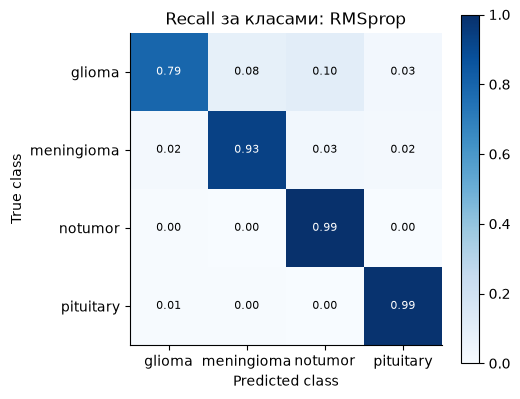

In [15]:
best_name = str(summary["test f1"].astype(float).idxmax())
best = results[best_name]
probs, targets = best.task.predict(test_loader)
preds = probs.argmax(dim=1)
print(f"Best by test F1: {best_name}")

matrix = confusion_matrix(preds, targets, num_classes=len(class_names))
saver.save(plot_confusion_matrix(matrix, class_names, title=f"Confusion matrix: {best_name}"), "confusion_counts")
saver.save(plot_confusion_matrix(matrix, class_names, normalize=True, title=f"Per-class recall: {best_name}"), "confusion_normalized")

num_classes = len(class_names)
pd.DataFrame(
    {
        "precision": MulticlassPrecision(num_classes=num_classes, average=None)(preds, targets).numpy(),
        "recall": MulticlassRecall(num_classes=num_classes, average=None)(preds, targets).numpy(),
        "support": matrix.sum(dim=1).numpy(),
    },
    index=class_names,
).round(4)

In [16]:
notumor = class_names.index("notumor")
false_negative = ((targets != notumor) & (preds == notumor)).nonzero().flatten()
false_positive = ((targets == notumor) & (preds != notumor)).nonzero().flatten()
wrong_type = ((targets != notumor) & (preds != notumor) & (preds != targets)).nonzero().flatten()
print(f"FN (tumor → notumor): {len(false_negative)}")
print(f"FP (notumor → tumor): {len(false_positive)}")
print(f"Wrong tumor type: {len(wrong_type)}")


def show_errors(indices: torch.Tensor, name: str, limit: int = 16) -> None:
    if len(indices) == 0:
        print(f"{name}: no errors")
        return
    order = probs[indices, preds[indices]].argsort(descending=True)
    chosen = indices[order][:limit].tolist()
    images = torch.stack([test_ds[i][0] for i in chosen])
    titles = [f"{class_names[targets[i]]} → {class_names[preds[i]]} ({probs[i, preds[i]]:.2f})" for i in chosen]
    saver.save(plot_image_grid(images, titles), name)

FN (пухлина → notumor): 53
FP (notumor → пухлина): 3
Неправильний тип пухлини: 64


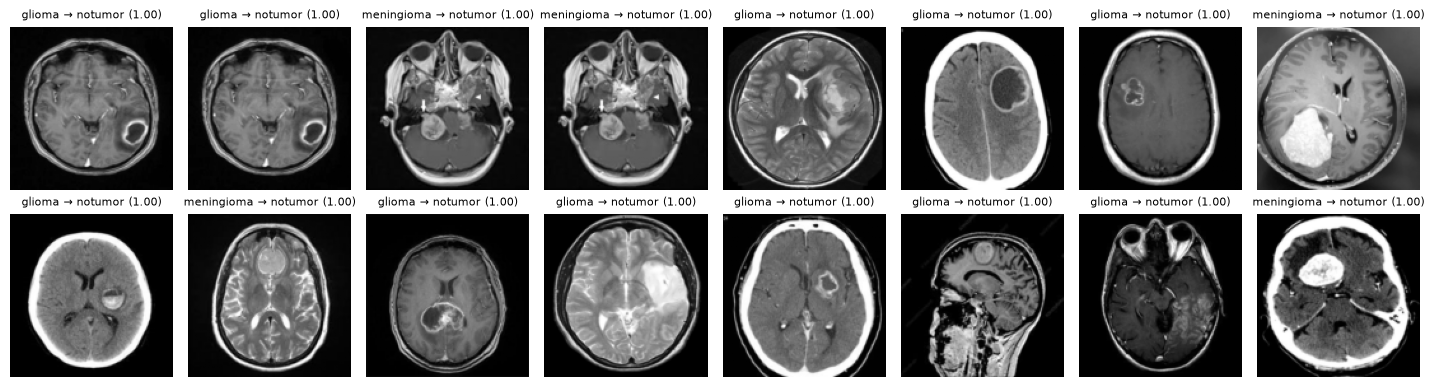

In [17]:
show_errors(false_negative, "false_negative")

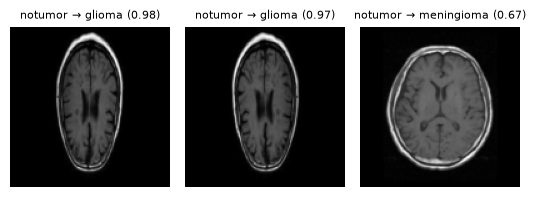

In [18]:
show_errors(false_positive, "false_positive")

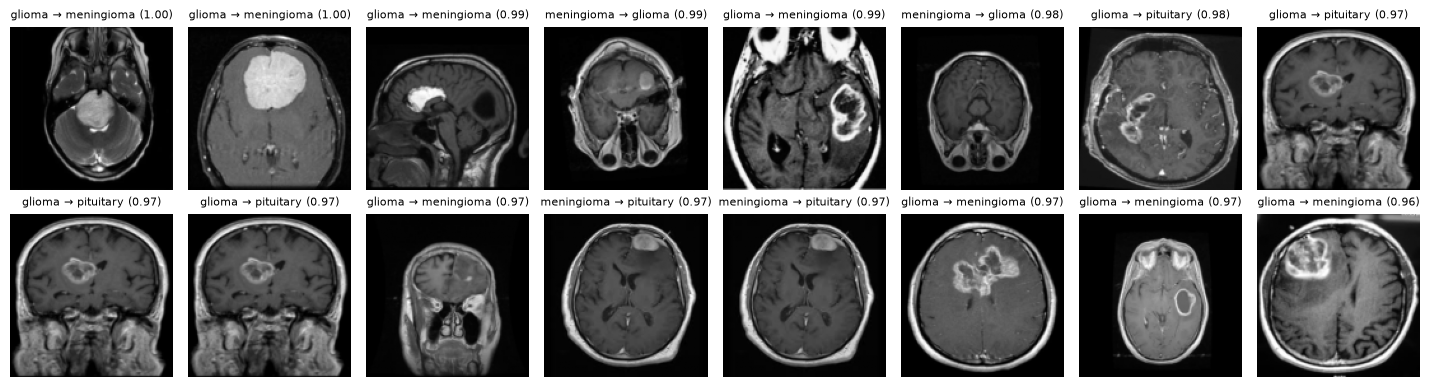

In [19]:
show_errors(wrong_type, "wrong_tumor_type")

In [20]:
import os
import shutil
import subprocess
import sys
import tempfile

os.environ["TENSORBOARD_BINARY"] = str(Path(sys.executable).parent / "tensorboard.exe")
subprocess.run(["taskkill", "/IM", "tensorboard.exe", "/T", "/F"], capture_output=True)
shutil.rmtree(Path(tempfile.gettempdir()) / ".tensorboard-info", ignore_errors=True)

%reload_ext tensorboard
%tensorboard --logdir runs